In [14]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

np.random.seed(42)
n = 600

df = pd.DataFrame({
    'Area': np.random.randint(500, 3500, n),
    'Bedrooms': np.random.randint(1, 6, n),
    'Age': np.random.randint(0, 35, n),
    'Distance': np.random.uniform(1, 25, n),
    'LocationScore': np.random.uniform(1, 10, n),
    'Parking': np.random.randint(0, 3, n),
    'Floor': np.random.randint(1, 20, n),
    'Noise1': np.random.normal(0, 1, n),
    'Noise2': np.random.normal(0, 1, n)
})

noise = np.random.normal(0, 3.0, n)
df['Price'] = (0.055*df.Area + 5*df.Bedrooms - 0.8*df.Age
               - 1.4*df.Distance + 9*df.LocationScore
               + 4*df.Parking + 0.3*df.Floor + noise)


In [15]:
df

,Area,Bedrooms,Age,Distance,LocationScore,Parking,Floor,Noise1,Noise2,Price
0,1360,5,17,23.581009,7.743553,0,9,0.261950,-0.293406,125.395263
1,1794,5,1,20.844133,3.615288,0,12,-1.255108,-1.449420,128.169632
2,1630,2,0,17.007316,8.082731,1,19,-0.351196,0.325841,163.338077
3,1595,2,4,14.852446,2.007423,2,3,2.684674,1.208348,106.230082
4,2138,2,19,9.365768,4.203760,1,15,-1.233269,1.141464,141.905927
...,...,...,...,...,...,...,...,...,...,...
595,3438,3,24,16.940510,8.730610,2,18,1.529297,-0.674191,259.970601
596,1992,5,3,6.186171,2.674207,2,16,0.131645,1.177545,159.648447
597,1667,3,32,3.341500,5.968624,0,7,-0.589567,-0.212579,132.250809
598,3116,4,0,21.687686,4.742178,2,4,-0.234335,-0.520864,217.861101


In [16]:
X = df.drop(columns='Price')
y = df['Price']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(df.head())

   Area  Bedrooms  Age   Distance  LocationScore  Parking  Floor    Noise1  \
0  1360         5   17  23.581009       7.743553        0      9  0.261950   
1  1794         5    1  20.844133       3.615288        0     12 -1.255108   
2  1630         2    0  17.007316       8.082731        1     19 -0.351196   
3  1595         2    4  14.852446       2.007423        2      3  2.684674   
4  2138         2   19   9.365768       4.203760        1     15 -1.233269   

     Noise2       Price  
0 -0.293406  125.395263  
1 -1.449420  128.169632  
2  0.325841  163.338077  
3  1.208348  106.230082  
4  1.141464  141.905927  


In [17]:
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

alphas = np.logspace(-4, 3, 100)

linear = LinearRegression()
ridge = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas=alphas, cv=5)
)

In [18]:
lasso = make_pipeline(
    StandardScaler(),
    LassoCV(alphas=alphas, cv=5, max_iter=20000, random_state=42)
)

In [19]:
linear.fit(X_train, y_train)
ridge.fit(X_train, y_train)
lasso.fit(X_train, y_train)


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('lassocv',
                 LassoCV(alphas=array([1.00000000e-04, 1.17681195e-04, 1.38488637e-04, 1.62975083e-04,
       1.91791026e-04, 2.25701972e-04, 2.65608778e-04, 3.12571585e-04,
       3.67837977e-04, 4.32876128e-04, 5.09413801e-04, 5.99484250e-04,
       7.05480231e-04, 8.30217568e-04, 9.77009957e-04, 1.14975700e-03,
       1.35304777e-03, 1.59228279...
       2.36448941e+01, 2.78255940e+01, 3.27454916e+01, 3.85352859e+01,
       4.53487851e+01, 5.33669923e+01, 6.28029144e+01, 7.39072203e+01,
       8.69749003e+01, 1.02353102e+02, 1.20450354e+02, 1.41747416e+02,
       1.66810054e+02, 1.96304065e+02, 2.31012970e+02, 2.71858824e+02,
       3.19926714e+02, 3.76493581e+02, 4.43062146e+02, 5.21400829e+02,
       6.13590727e+02, 7.22080902e+02, 8.49753436e+02, 1.00000000e+03]),
                         cv=5, max_iter=20000, random_state=42))])

In [20]:
print('Best Ridge alpha:', ridge.named_steps['ridgecv'].alpha_)
print('Best Lasso alpha:', lasso.named_steps['lassocv'].alpha_)

Best Ridge alpha: 0.0001
Best Lasso alpha: 0.021544346900318822


In [21]:
models = {
    'Linear': linear,
    'Ridge': ridge,
    'Lasso': lasso
}

In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
results = []
for name, model in models.items():
    pred = model.predict(X_test)
    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'R2': r2_score(y_test, pred)
    })

results = pd.DataFrame(results).sort_values('RMSE')
print(results)

    Model       MAE      RMSE        R2
2   Lasso  2.287400  2.827163  0.996949
1   Ridge  2.295996  2.836043  0.996930
0  Linear  2.295998  2.836043  0.996930


In [23]:
ridge_coef = ridge.named_steps['ridgecv'].coef_
lasso_coef = lasso.named_steps['lassocv'].coef_

coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Ridge_Coefficient': ridge_coef,
    'Lasso_Coefficient': lasso_coef
})
print(coef_df)

         Feature  Ridge_Coefficient  Lasso_Coefficient
0           Area          46.341372          46.321225
1       Bedrooms           7.021280           7.003382
2            Age          -7.767771          -7.745800
3       Distance          -9.526700          -9.503719
4  LocationScore          23.777737          23.755442
5        Parking           3.629673           3.608501
6          Floor           1.732008           1.707937
7         Noise1           0.218289           0.200275
8         Noise2           0.148469           0.122213


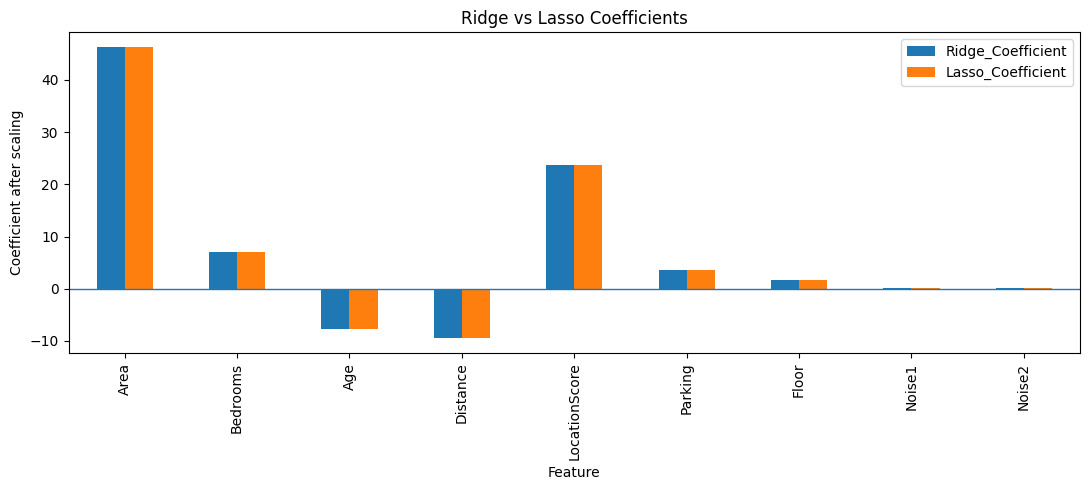

In [24]:
import matplotlib.pyplot as plt
plot_df = coef_df.set_index('Feature')
plot_df.plot(kind='bar', figsize=(11,5))
plt.axhline(0, linewidth=1)
plt.title('Ridge vs Lasso Coefficients')
plt.ylabel('Coefficient after scaling')
plt.tight_layout()
plt.show()

In [26]:
new_house = pd.DataFrame([{
    'Area': 3000,
    'Bedrooms': 3,
    'Age': 8,
    'Distance': 6.5,
    'LocationScore': 8.2,
    'Parking': 1,
    'Floor': 5,
    'Noise1': 0.1,
    'Noise2': -0.2
}])

for name, model in models.items():
    print(name, 'Predicted Price:', round(model.predict(new_house)[0], 2))

Linear Predicted Price: 242.93
Ridge Predicted Price: 242.93
Lasso Predicted Price: 242.87
